# Python Assignment 7 : MLR

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('ToyotaCorolla - MLR.csv')
data.head()

,Price,Age_08_04,KM,Fuel_Type,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
0,13500,23,46986,Diesel,90,0,2000,3,4,5,1165
1,13750,23,72937,Diesel,90,0,2000,3,4,5,1165
2,13950,24,41711,Diesel,90,0,2000,3,4,5,1165
3,14950,26,48000,Diesel,90,0,2000,3,4,5,1165
4,13750,30,38500,Diesel,90,0,2000,3,4,5,1170


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1436 entries, 0 to 1435
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Price      1436 non-null   int64
 1   Age_08_04  1436 non-null   int64
 2   KM         1436 non-null   int64
 3   Fuel_Type  1436 non-null   str  
 4   HP         1436 non-null   int64
 5   Automatic  1436 non-null   int64
 6   cc         1436 non-null   int64
 7   Doors      1436 non-null   int64
 8   Cylinders  1436 non-null   int64
 9   Gears      1436 non-null   int64
 10  Weight     1436 non-null   int64
dtypes: int64(10), str(1)
memory usage: 123.5 KB


In [4]:
data.dtypes

Price        int64
Age_08_04    int64
KM           int64
Fuel_Type      str
HP           int64
Automatic    int64
cc           int64
Doors        int64
Cylinders    int64
Gears        int64
Weight       int64
dtype: object

In [5]:
data.isna().sum()

Price        0
Age_08_04    0
KM           0
Fuel_Type    0
HP           0
Automatic    0
cc           0
Doors        0
Cylinders    0
Gears        0
Weight       0
dtype: int64

In [6]:
data.describe()

,Price,Age_08_04,KM,HP,Automatic,cc,Doors,Cylinders,Gears,Weight
count,1436.000000,1436.000000,1436.000000,1436.000000,1436.000000,1436.00000,1436.000000,1436.0,1436.000000,1436.00000
mean,10730.824513,55.947075,68533.259749,101.502089,0.055710,1576.85585,4.033426,4.0,5.026462,1072.45961
std,3626.964585,18.599988,37506.448872,14.981080,0.229441,424.38677,0.952677,0.0,0.188510,52.64112
min,4350.000000,1.000000,1.000000,69.000000,0.000000,1300.00000,2.000000,4.0,3.000000,1000.00000
25%,8450.000000,44.000000,43000.000000,90.000000,0.000000,1400.00000,3.000000,4.0,5.000000,1040.00000
50%,9900.000000,61.000000,63389.500000,110.000000,0.000000,1600.00000,4.000000,4.0,5.000000,1070.00000
75%,11950.000000,70.000000,87020.750000,110.000000,0.000000,1600.00000,5.000000,4.0,5.000000,1085.00000
max,32500.000000,80.000000,243000.000000,192.000000,1.000000,16000.00000,5.000000,4.0,6.000000,1615.00000


#### data visualization

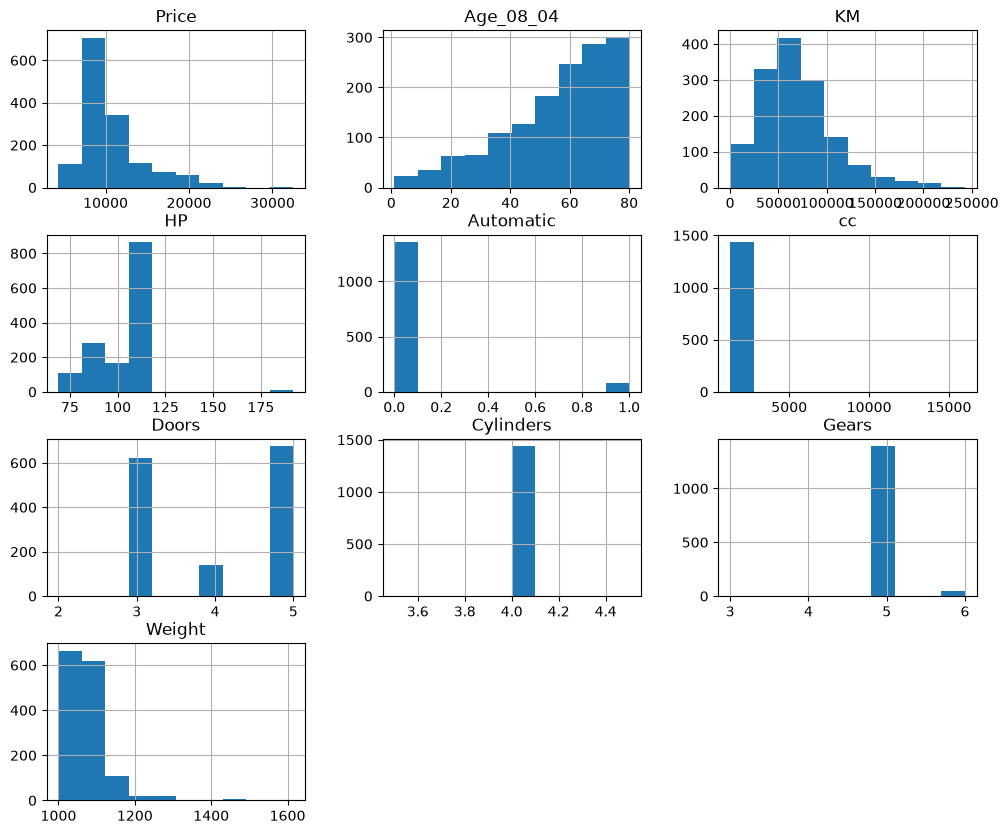

In [7]:
data.hist(figsize=(12,10))
plt.show()


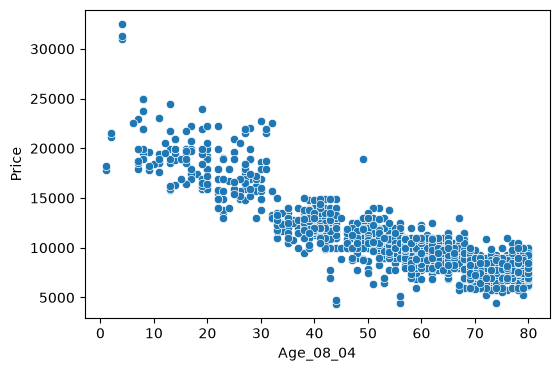

In [8]:
plt.figure(figsize=(6,4))
sns.scatterplot(data, x='Age_08_04', y='Price')
plt.show()

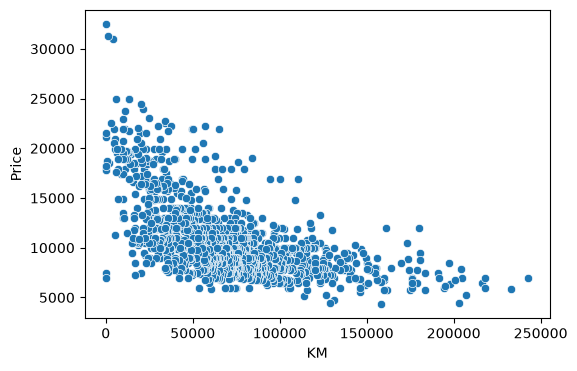

In [9]:
plt.figure(figsize=(6,4))
sns.scatterplot(data, x='KM', y='Price')
plt.show()

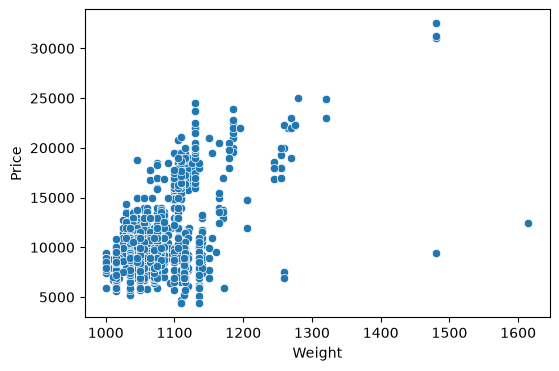

In [10]:
plt.figure(figsize=(6,4))
sns.scatterplot(data, x='Weight', y='Price')
plt.show()

#### data preprocessing

In [11]:
from sklearn.preprocessing import  LabelEncoder

In [12]:
# encoding
enc = LabelEncoder()
data['Fuel_Type'] = enc.fit_transform(data['Fuel_Type'])


In [13]:
#data.head()

In [14]:
from sklearn.preprocessing import  StandardScaler

In [15]:
# scaling
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)
scaled_data = pd.DataFrame(scaled_data)


In [16]:
#scaled_data.head()

In [17]:
# split the data
X = data.drop('Price', axis=1)
y = data['Price']

In [18]:
data1 = data.loc[:, data.nunique() > 1]


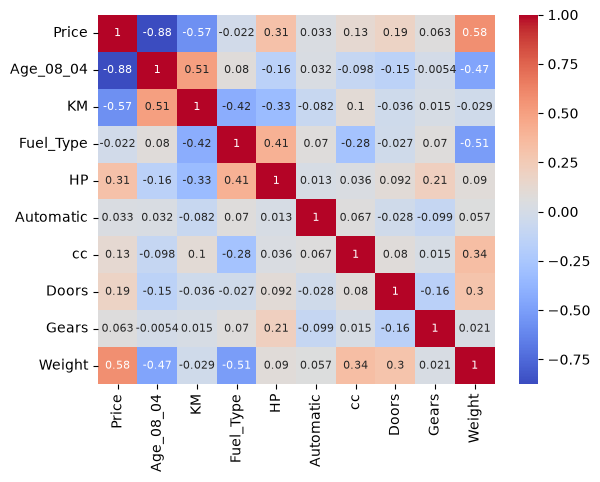

In [19]:
sns.heatmap(data1.corr(), annot=True, cmap='coolwarm', annot_kws={'size':8})
plt.show()

In [20]:
from sklearn.model_selection import train_test_split

### training the data

#### model 1

In [21]:
# split data
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(1148, 10) (288, 10) (1148,) (288,)


In [22]:
from sklearn.linear_model import LinearRegression

In [23]:
# build model
model1 = LinearRegression()
model1.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[-121.44, -0.02, 862.06,..., 0. , 530.28, 23.51]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['Age_08_04','KM','Fuel_Type',...,'Cylinders','Gears','Weight']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.264e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(9)


In [24]:
#make prediction
yhat_train =model1.predict(X_train)

In [25]:
model1.coef_

array([-1.21436240e+02, -1.69355966e-02,  8.62056431e+02,  2.06582831e+01,
        2.45196891e+02, -7.35153881e-02, -3.62796477e+01,  4.54747351e-13,
        5.30282040e+02,  2.35106426e+01])

#### model 2

In [26]:
X2 = data[['Age_08_04','KM','Fuel_Type','HP','Automatic','cc','Weight']]

In [27]:
# split data
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y, test_size=0.2, random_state=42)

print(X_train2.shape, X_test2.shape, y_train2.shape, y_test2.shape)


(1148, 7) (288, 7) (1148,) (288,)


In [28]:
# build model
model2 = LinearRegression()
model2.fit(X_train2, y_train2)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-121.44, -0.02, 859.6 ,..., 201.8 , -0.07, 23.31]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Age_08_04','KM','Fuel_Type',...,'Automatic','cc','Weight']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.006e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [29]:
#make prediction
yhat_train2 = model2.predict(X_train2)

In [30]:
model2.coef_

array([-1.21444452e+02, -1.67049436e-02,  8.59598131e+02,  2.21573441e+01,
        2.01799851e+02, -7.03368514e-02,  2.33059004e+01])

#### model 3

In [31]:
X3 = data[['Age_08_04','KM','HP','Weight']]

In [32]:
# split data
X_train3, X_test3, y_train3, y_test3 = train_test_split(
    X3, y, test_size=0.2, random_state=42)

print(X_train3.shape, X_test3.shape, y_train3.shape, y_test3.shape)


(1148, 4) (288, 4) (1148,) (288,)


In [33]:
# build model
model3 = LinearRegression()
model3.fit(X_train3, y_train3)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-120.03, -0.02, 29.05, 19.77]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['Age_08_04','KM','HP','Weight']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-5305
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [34]:
#make prediction
yhat_train3 = model3.predict(X_train3)

In [35]:
model3.coef_

array([-1.20025405e+02, -2.02325920e-02,  2.90521704e+01,  1.97690662e+01])

### testing the data

In [36]:
# model1 testing
yhat_test1 = model1.predict(X_test)

In [37]:
# model2 testing
yhat_test2 = model2.predict(X_test2)

In [38]:
# model3 testing
yhat_test3 = model3.predict(X_test3)

#### Evalution of model

In [39]:
# evaluate the model
from sklearn.metrics import mean_squared_error, r2_score

##### model 1 evaluation

In [40]:
# model1 training  evaluation
mse =  mean_squared_error(y_train,yhat_train)
rmse = np.sqrt(mse)
r2_sqr =  r2_score(y_train,yhat_train)

print(f"mse : {np.round(mse,2)}")
print(f"rmse : {np.round(rmse,2)}")
print(f"r2 : {np.round(r2_sqr,2)}")

mse : 1708659.49
rmse : 1307.16
r2 : 0.87


In [41]:
# model1 testing evaluation
mse_test1 = mean_squared_error(y_test, yhat_test1)
rmse_test1 = np.sqrt(mse_test1)
r2_test1 = r2_score(y_test, yhat_test1)

print(f"Test MSE : {np.round(mse_test1,2)}")
print(f"Test RMSE : {np.round(rmse_test1,2)}")
print(f"Test R2 : {np.round(r2_test1,2)}")


Test MSE : 2096851.14
Test RMSE : 1448.05
Test R2 : 0.84


In [42]:
print("Train R2:", r2_sqr)
print("Test R2:", r2_test1)


Train R2: 0.8695032279244472
Test R2: 0.8428476112018


##### model2 evaluation

In [43]:
# model2 training evaluation
mse2 = mean_squared_error(y_train2, yhat_train2)
rmse2 = np.sqrt(mse2)
r2_sqr2 = r2_score(y_train2, yhat_train2)

print(f"MSE : {np.round(mse2,2)}")
print(f"RMSE : {np.round(rmse2,2)}")
print(f"R2 : {np.round(r2_sqr2,2)}")


MSE : 1721535.62
RMSE : 1312.07
R2 : 0.87


In [44]:
# model2 testing evaluation
mse_test2 = mean_squared_error(y_test2, yhat_test2)
rmse_test2 = np.sqrt(mse_test2)
r2_test2 = r2_score(y_test2, yhat_test2)

print(f"Test MSE : {np.round(mse_test2,2)}")
print(f"Test RMSE : {np.round(rmse_test2,2)}")
print(f"Test R2 : {np.round(r2_test2,2)}")


Test MSE : 2119618.18
Test RMSE : 1455.89
Test R2 : 0.84


In [45]:
print("Train R2:", r2_sqr2)
print("Test R2:", r2_test2)


Train R2: 0.8685198295614223
Test R2: 0.8411412931306532


##### model3 evaluation

In [46]:
# model3 evaluation
mse3= mean_squared_error(y_train3, yhat_train3)
rmse3 = np.sqrt(mse3)
r2_sqr3 = r2_score(y_train3, yhat_train3)

print(f"MSE : {np.round(mse3,2)}")
print(f"RMSE : {np.round(rmse3,2)}")
print(f"R2 : {np.round(r2_sqr3,2)}")


MSE : 1776992.83
RMSE : 1333.04
R2 : 0.86


In [47]:
# model3 testing evaluation
mse_test3 = mean_squared_error(y_test3, yhat_test3)
rmse_test3 = np.sqrt(mse_test3)
r2_test3 = r2_score(y_test3, yhat_test3)

print(f"Test MSE : {np.round(mse_test3,2)}")
print(f"Test RMSE : {np.round(rmse_test3,2)}")
print(f"Test R2 : {np.round(r2_test3,2)}")


Test MSE : 1993321.01
Test RMSE : 1411.85
Test R2 : 0.85


In [48]:
print("Train R2:", r2_sqr3)
print("Test R2:", r2_test3)


Train R2: 0.8642843529878648
Test R2: 0.8506068681500583


#### Lasso and Ridge

In [49]:
from sklearn.linear_model import LinearRegression,Lasso, Ridge, ElasticNet

In [50]:
params = pd.DataFrame(model1.coef_, columns=['MLR'], index=X.columns)
params

,MLR
Age_08_04,-1.214362e+02
KM,-1.693560e-02
Fuel_Type,8.620564e+02
HP,2.065828e+01
Automatic,2.451969e+02
cc,-7.351539e-02
Doors,-3.627965e+01
Cylinders,4.547474e-13
Gears,5.302820e+02
Weight,2.351064e+01


In [51]:
# model
lasso = Lasso(alpha=1.0)
lasso.fit(X,y)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [52]:
lasso.coef_

array([-1.23718956e+02, -1.75955474e-02,  5.63426274e+02,  2.38722421e+01,
        2.81674537e+02, -5.72943003e-02, -2.95966226e+01,  0.00000000e+00,
        5.90696649e+02,  2.07327297e+01])

In [53]:
params['Lasso'] = lasso.coef_
params

,MLR,Lasso
Age_08_04,-1.214362e+02,-123.718956
KM,-1.693560e-02,-0.017596
Fuel_Type,8.620564e+02,563.426274
HP,2.065828e+01,23.872242
Automatic,2.451969e+02,281.674537
cc,-7.351539e-02,-0.057294
Doors,-3.627965e+01,-29.596623
Cylinders,4.547474e-13,0.000000
Gears,5.302820e+02,590.696649
Weight,2.351064e+01,20.732730


In [54]:
ridge = Ridge(alpha=1.0)
ridge.fit(X,y)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [55]:
ridge.coef_

array([-1.23767111e+02, -1.75562431e-02,  5.71905740e+02,  2.37592410e+01,
        2.97595986e+02, -5.72539298e-02, -3.02373067e+01,  0.00000000e+00,
        6.08742827e+02,  2.07571057e+01])

In [56]:
params['ridge'] = ridge.coef_
params

,MLR,Lasso,ridge
Age_08_04,-1.214362e+02,-123.718956,-123.767111
KM,-1.693560e-02,-0.017596,-0.017556
Fuel_Type,8.620564e+02,563.426274,571.905740
HP,2.065828e+01,23.872242,23.759241
Automatic,2.451969e+02,281.674537,297.595986
cc,-7.351539e-02,-0.057294,-0.057254
Doors,-3.627965e+01,-29.596623,-30.237307
Cylinders,4.547474e-13,0.000000,0.000000
Gears,5.302820e+02,590.696649,608.742827
Weight,2.351064e+01,20.732730,20.757106


### interview questions

#### 1.What is Normalization & Standardization and how is it helpful?

#### 2.What techniques can be used to address multicollinearity in multiple linear regression?